In [9]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

# load + index
df = pd.read_csv('dataset/ec2_cpu_utilization_5f5533.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp').sort_index()

# labels
with open('dataset/combined_windows.json') as f:
    labels = json.load(f)
key = 'realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv'
windows = [[pd.to_datetime(s), pd.to_datetime(e)] for s, e in labels[key]]

# ground-truth mask
mask = pd.Series(False, index=df.index)
for start, end in windows:
    mask |= (df.index >= start) & (df.index <= end)
df['is_anomaly'] = mask

In [10]:
df

,value,is_anomaly
timestamp,,
2014-02-14 14:27:00,51.846,False
2014-02-14 14:32:00,44.508,False
2014-02-14 14:37:00,41.244,False
2014-02-14 14:42:00,48.568,False
2014-02-14 14:47:00,46.714,False
...,...,...
2014-02-28 14:02:00,38.474,False
2014-02-28 14:07:00,40.352,False
2014-02-28 14:12:00,37.912,False


In [11]:
mask.mean()

np.float64(0.09970238095238096)

In [12]:
roll_mean = df['value'].rolling(12).mean()
df['roll_std'] = df['value'].rolling(12).std()
df['abs_dev'] = (df['value'] - roll_mean).abs()
df['change'] = df['value'].diff().abs()

# rolling features are NaN for the first 11 rows, drop them
df = df.dropna().copy()

In [13]:
df.shape

(4021, 5)

In [14]:
features = ['abs_dev', 'roll_std', 'change']
X = df[features]

model = IsolationForest(contamination=0.10, random_state=42)
df['predicted'] = model.fit_predict(X)

# sklearn returns -1 for anomaly, 1 for normal. flip to boolean.
df['predicted_anomaly'] = df['predicted'] == -1

print(f"Flagged {df['predicted_anomaly'].sum()} points as anomalies")

Flagged 402 points as anomalies


In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

y_true = df['is_anomaly']
y_pred = df['predicted_anomaly']

print("Precision:", round(precision_score(y_true, y_pred), 3))
print("Recall:   ", round(recall_score(y_true, y_pred), 3))
print("F1:       ", round(f1_score(y_true, y_pred), 3))
print()
print(confusion_matrix(y_true, y_pred))

Precision: 0.172
Recall:    0.172
F1:        0.172

[[3286  333]
 [ 333   69]]


In [16]:
for i, (start, end) in enumerate(windows, 1):
    win = df.loc[start:end]
    caught = win['predicted_anomaly'].any()
    n_flags = win['predicted_anomaly'].sum()
    print(f"Window {i} ({start.date()}): {'CAUGHT' if caught else 'MISSED'}, {n_flags} flags inside")

Window 1 (2014-02-18): CAUGHT, 38 flags inside
Window 2 (2014-02-24): CAUGHT, 31 flags inside


In [17]:
for c in [0.10, 0.12, 0.15]:
    m = IsolationForest(contamination=c, random_state=42)
    pred = m.fit_predict(X) == -1
    p = precision_score(y_true, pred)
    r = recall_score(y_true, pred)
    f = f1_score(y_true, pred)
    print(f"contamination={c}: precision={p:.3f} recall={r:.3f} f1={f:.3f}")

contamination=0.1: precision=0.172 recall=0.172 f1=0.172
contamination=0.12: precision=0.166 recall=0.199 f1=0.181
contamination=0.15: precision=0.153 recall=0.229 f1=0.183


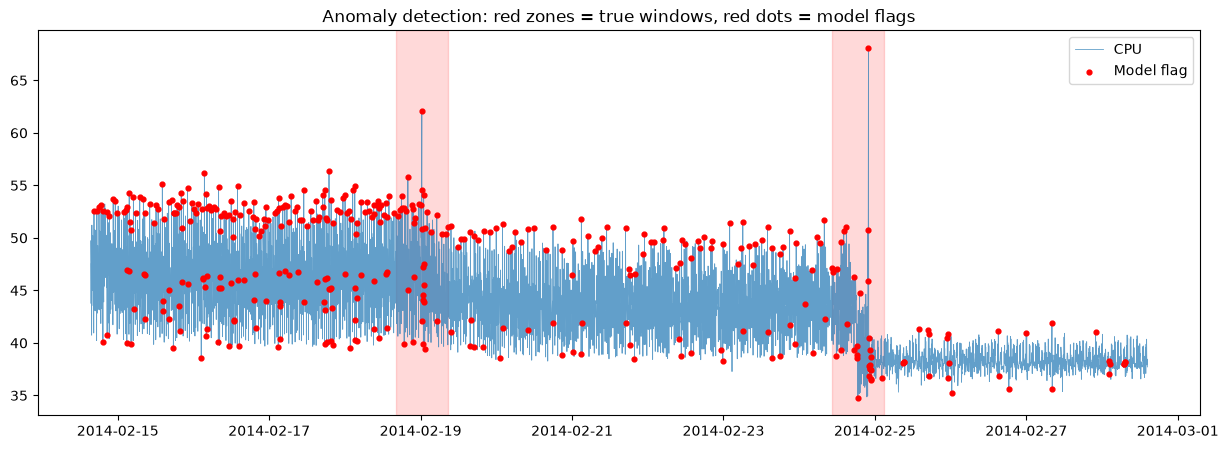

In [18]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], linewidth=0.6, alpha=0.7, label='CPU')

for start, end in windows:
    plt.axvspan(start, end, color='red', alpha=0.15)

flagged = df[df['predicted_anomaly']]
plt.scatter(flagged.index, flagged['value'], color='red', s=12, label='Model flag', zorder=5)

plt.title('Anomaly detection: red zones = true windows, red dots = model flags')
plt.legend()
plt.show()

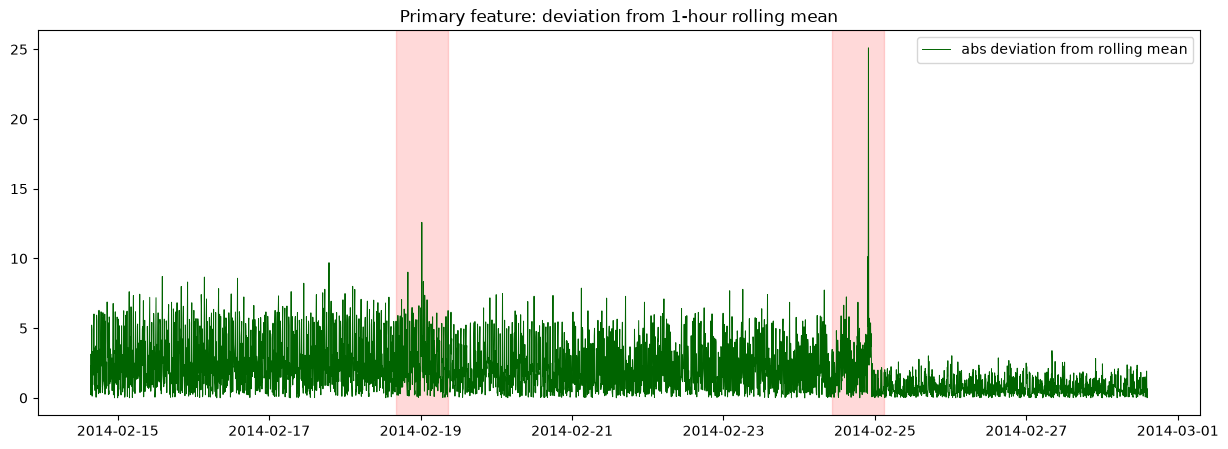

In [19]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['abs_dev'], linewidth=0.7, color='darkgreen', label='abs deviation from rolling mean')

for start, end in windows:
    plt.axvspan(start, end, color='red', alpha=0.15)

plt.title('Primary feature: deviation from 1-hour rolling mean')
plt.legend()
plt.show()